# ДЗ 1. Рекомендательные системы

Смирнов Евгений Максимович, Б05-326.

Датасет: Amazon Review Data 2018, категория Musical Instruments, 5-core. Источник: https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/ , статья Ni, Li, McAuley, EMNLP 2019.

Запуск: скачать два файла в папку data рядом с ноутбуком, установить зависимости из requirements.txt и выполнить ячейки по порядку. Если файлов нет, следующая ячейка скачает их сама.

In [2]:
import os, time, random, urllib.request
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import torch

from common import read_jsonl_gz, parse_price, clean_categories, TrainSet, build_ground_truth, evaluate, rating_arrays
from models import Popular, ItemKNN, IALS, EASE, FM, TimeSVDpp

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())

DATA_DIR = "data"
BASE = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/"
FILES = {
    "Musical_Instruments_5.json.gz": BASE + "categoryFilesSmall/Musical_Instruments_5.json.gz",
    "meta_Musical_Instruments.json.gz": BASE + "metaFiles2/meta_Musical_Instruments.json.gz",
}
os.makedirs(DATA_DIR, exist_ok=True)
for name, url in FILES.items():
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
K = 10

## 1. Данные

Отзыв на Amazon означает, что пользователь купил товар. Рекомендуем товары, которые пользователь купит в будущем. Релевантный объект: товар, купленный пользователем в оцениваемом периоде и оценённый на 4 или 5.

Поля отзывов: reviewerID это пользователь, asin это товар, overall это оценка 1–5, unixReviewTime это дата отзыва. Поля метаданных: asin, title, brand, category это путь в дереве категорий, price.

In [3]:
reviews = read_jsonl_gz(os.path.join(DATA_DIR, "Musical_Instruments_5.json.gz"),
                        ["reviewerID", "asin", "overall", "unixReviewTime", "verified"])
meta = read_jsonl_gz(os.path.join(DATA_DIR, "meta_Musical_Instruments.json.gz"),
                     ["asin", "title", "brand", "category", "price"])
print("отзывов:", len(reviews), "товаров в метаданных:", len(meta))
reviews.head()

отзывов: 231392 товаров в метаданных: 120310


,reviewerID,asin,overall,unixReviewTime,verified
0,A3FO5AKVTFRCRJ,0739079891,5.0,1477785600,True
1,A3UCGC1DHFMBCE,0739079891,5.0,1467244800,True
2,A2S9SLRYLPGYZB,0739079891,5.0,1462752000,True
3,A15RTJWPG8OKOE,0739079891,4.0,1460246400,True
4,A12ET1WO3OAVU7,0739079891,1.0,1454716800,True


## 2. EDA и подготовка

In [4]:
print("пропуски в отзывах:"); print(reviews.isna().sum())
df = reviews.rename(columns={"reviewerID": "user_id", "asin": "item_id", "overall": "rating", "unixReviewTime": "ts"})
df = df.dropna(subset=["user_id", "item_id", "rating", "ts"])
print("полные дубликаты строк:", df.duplicated().sum())
print("повторные пары пользователь-товар:", df.duplicated(["user_id", "item_id"]).sum())
df = df.sort_values("ts").drop_duplicates(["user_id", "item_id"], keep="first").reset_index(drop=True)
df["rating"] = df["rating"].astype(float)
df["day"] = (df["ts"] // 86400).astype(int)
df["date"] = pd.to_datetime(df["ts"], unit="s")
nu, ni = df.user_id.nunique(), df.item_id.nunique()
print(f"после очистки: {len(df)} взаимодействий, {nu} пользователей, {ni} товаров, плотность {len(df)/nu/ni:.5f}")
print("период:", df.date.min().date(), "-", df.date.max().date())

пропуски в отзывах:
reviewerID        0
asin              0
overall           0
unixReviewTime    0
verified          0
dtype: int64
полные дубликаты строк: 10209
повторные пары пользователь-товар: 12236
после очистки: 219156 взаимодействий, 27530 пользователей, 10620 товаров, плотность 0.00075
период: 2003-10-28 - 2018-09-28


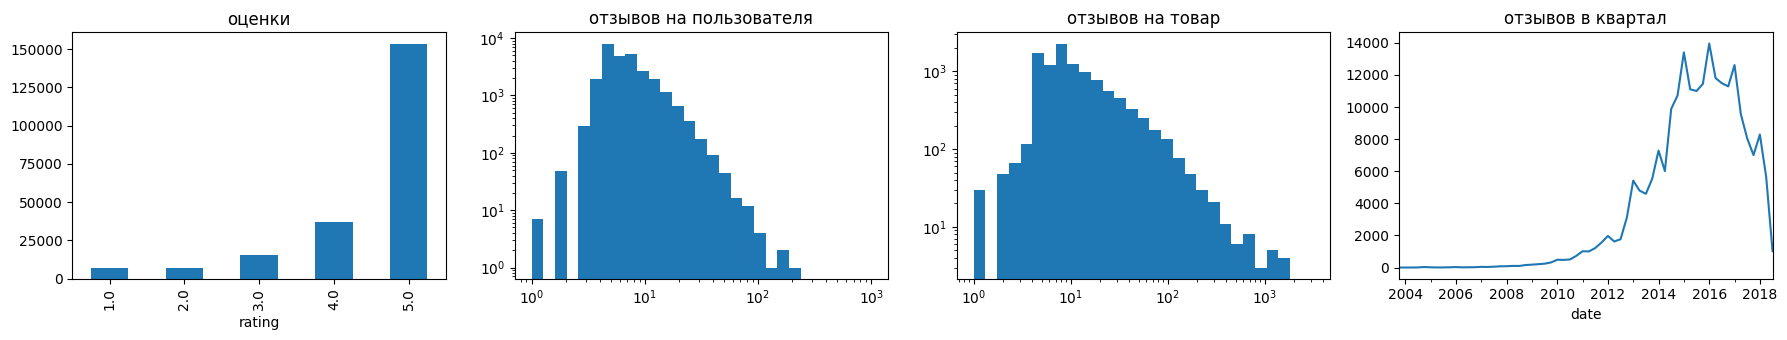

{'count': 27530.0, 'mean': 8.0, 'std': 5.9, 'min': 1.0, '25%': 5.0, '50%': 6.0, '75%': 9.0, 'max': 229.0}
{'count': 10620.0, 'mean': 20.6, 'std': 58.2, 'min': 1.0, '25%': 6.0, '50%': 9.0, '75%': 18.0, 'max': 1756.0}


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
df.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="оценки")
ax[1].hist(df.groupby("user_id").size(), bins=np.logspace(0, 3, 30)); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_title("отзывов на пользователя")
ax[2].hist(df.groupby("item_id").size(), bins=np.logspace(0, 3.5, 30)); ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_title("отзывов на товар")
df.set_index("date").resample("QE").size().plot(ax=ax[3], title="отзывов в квартал")
plt.tight_layout(); plt.show()
print(df.groupby("user_id").size().describe().round(1).to_dict())
print(df.groupby("item_id").size().describe().round(1).to_dict())

товаров с метаданными: 10611 из 10620
есть бренд: 0.992  есть цена: 0.767  есть категории: 0.974
брендов: 1719
cats
Instrument Accessories        5006
Live Sound & Stage            1033
Amplifiers & Effects           940
Microphones & Accessories      852
Studio Recording Equipment     757
Guitars                        476
Drums & Percussion             372
нет                            281
Name: count, dtype: int64


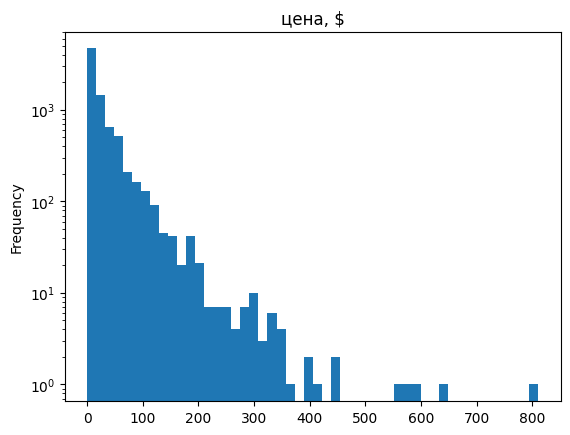

In [6]:
meta = meta.drop_duplicates("asin").set_index("asin")
meta = meta.loc[meta.index.intersection(df.item_id.unique())].copy()
meta["price_num"] = meta["price"].map(parse_price)
meta["cats"] = meta["category"].map(clean_categories)
meta["brand"] = meta["brand"].fillna("").astype(str).str.strip()
print("товаров с метаданными:", len(meta), "из", ni)
print("есть бренд:", round((meta.brand != "").mean(), 3), " есть цена:", round(meta.price_num.notna().mean(), 3),
      " есть категории:", round((meta.cats.str.len() > 0).mean(), 3))
print("брендов:", meta.brand.nunique())
print(meta.cats.map(lambda c: c[0] if c else "нет").value_counts().head(8))
meta.price_num.dropna().clip(upper=1000).plot.hist(bins=50, log=True, title="цена, $"); plt.show()

Выборка уже 5-core, объём попадает в требуемые рамки, поэтому подвыборку не делаем. Удаляем повторные отзывы на тот же товар, оставляя первый. Из метаданных берём только бренд, категории и цену. Поля rank, also_buy, also_view собраны в 2018 году и содержат информацию из будущего, их не используем.

## 3. Протокол оценки

Глобальное разбиение по времени: train до 80-го перцентиля дат, validation с 80-го до 90-го, test после 90-го. Гиперпараметры подбираем: обучение на train, оценка на validation. Финал: обучение на train+validation с выбранными параметрами, оценка на test.

Кандидаты: все товары из обучающей части. Уже купленные пользователем товары исключаем из выдачи. Новые пользователи без истории не оцениваются, им в продакшене отдали бы популярное. Новые товары не попадают в кандидаты, их покупки убираем из ground truth. Правила одинаковы для всех моделей, релевантность не зависит от таргета модели.

Метрики при K = 10. Основная NDCG@10, выбрана до подбора: учитывает позицию релевантного товара в выдаче. Также Recall@10, доля будущих покупок, попавших в top-10, и HR@10, доля пользователей хотя бы с одним попаданием. Coverage@10 показывает разнообразие выдачи.

In [7]:
q80, q90 = df.ts.quantile([0.8, 0.9]).to_numpy()
train = df[df.ts < q80]; val = df[(df.ts >= q80) & (df.ts < q90)]; test = df[df.ts >= q90]
trainval = df[df.ts < q90]
print("границы:", pd.to_datetime(q80, unit="s").date(), pd.to_datetime(q90, unit="s").date())
print("размеры:", len(train), len(val), len(test))


def item_features(ts, meta, min_brand=5, n_price_bins=8):
    m = meta.reindex(ts.items)
    feats = []
    brand = m["brand"].fillna("")
    vc = brand.value_counts()
    brand = brand.where(brand.map(vc).fillna(0) >= min_brand, "other").replace("", "unknown")
    feats.append([["brand=" + b] for b in brand])
    cats = m["cats"].map(lambda c: c if isinstance(c, list) else [])
    feats.append([[f"cat{l}=" + x for l, x in enumerate(c)] for c in cats])
    p = np.log1p(m["price_num"].to_numpy(dtype=float))
    edges = np.nanquantile(p, np.linspace(0, 1, n_price_bins + 1)[1:-1]) if np.isfinite(p).any() else []
    pb = np.where(np.isnan(p), -1, np.searchsorted(edges, np.nan_to_num(p)))
    feats.append([[f"price={b}"] for b in pb])
    rows = [sum(parts, []) for parts in zip(*feats)]
    vocab = {f: j for j, f in enumerate(sorted({f for r in rows for f in r}))}
    data, ri, ci = [], [], []
    for r, fs in enumerate(rows):
        w = 1.0 / np.sqrt(len(fs))
        for f in fs:
            ri.append(r); ci.append(vocab[f]); data.append(w)
    return sp.csr_matrix((data, (ri, ci)), shape=(len(rows), len(vocab))), vocab


def user_features(ts, item_cat, n_bins=6):
    cnt = np.bincount(ts.u, minlength=ts.n_users)
    act = np.minimum(np.log2(cnt).astype(int), n_bins - 1)
    A = sp.csr_matrix((np.ones(ts.n_users), (np.arange(ts.n_users), act)), shape=(ts.n_users, n_bins))
    prof = ts.X @ item_cat
    prof = sp.diags(1.0 / np.maximum(np.asarray(prof.sum(1)).ravel(), 1e-9)) @ prof
    return sp.hstack([A, prof]).tocsr().astype(np.float32)


def make_trainset(part, t_rec):
    ts = TrainSet(part, t_rec=t_rec // 86400)
    ts.item_features, vocab = item_features(ts, meta)
    cat_cols = [j for f, j in vocab.items() if f.startswith("cat")]
    item_cat = (ts.item_features[:, cat_cols] > 0).astype(np.float32)
    ts.user_features = user_features(ts, item_cat)
    return ts


ts_val = make_trainset(train, q80)
ts_test = make_trainset(trainval, q90)
gt_val = build_ground_truth(ts_val, val)
gt_test = build_ground_truth(ts_test, test)
print("val: пользователей в оценке", len(gt_val), " test:", len(gt_test))
print("признаков товара:", ts_val.item_features.shape[1], " признаков пользователя:", ts_val.user_features.shape[1])

границы: 2017-02-27 2017-10-01
размеры: 175204 21993 21959
val: пользователей в оценке 5653  test: 5754
признаков товара: 874  признаков пользователя: 484


## 4. Модели

Popular. Бейзлайн для сравнения: самые популярные товары в train.

ItemKNN. Сходство товаров по бинарной матрице $X$: $s_{ij} = \frac{x_i^\top x_j}{\|x_i\|\|x_j\| + h}$, $h$ это сжатие. Для каждого товара оставляем $k$ ближайших соседей. Скор: $\hat r_{ui} = \sum_{j \in I_u} s_{ji}$.

iALS. $\min_{X,Y} \sum_{u,i} c_{ui}(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2)$, где $p_{ui} = 1$ для покупок и 0 иначе, $c_{ui} = 1 + \alpha p_{ui}$. Попеременно решаем $x_u = (Y^\top C_u Y + \lambda I)^{-1} Y^\top C_u p_u$ и аналогично для $y_i$, используя $Y^\top C_u Y = Y^\top Y + Y^\top (C_u - I) Y$.

EASE. $\min_B \|X - XB\|_F^2 + \lambda\|B\|_F^2$ при $\mathrm{diag}(B) = 0$. Решение: $P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij}/P_{jj}$. Скор: $XB$.

FM. $\hat y(x) = w_0 + \sum_f w_f x_f + \sum_{f<g} \langle v_f, v_g\rangle x_f x_g$. Признаки пользователя: ID, корзина активности в train, профиль категорий его прошлых покупок. Признаки товара: ID, бренд, категории всех уровней, корзина цены. Все признаки известны в момент рекомендации: профиль считается только по train, бренд, категории и цена это статичные свойства товара. Обучение BPR: $-\log\sigma(\hat y_{ui} - \hat y_{uj})$ со случайным негативом $j$.

timeSVD++. $\hat r_{ui}(t) = \mu + b_u + \alpha_u \mathrm{dev}_u(t) + b_{u,t} + (b_i + b_{i,\mathrm{Bin}(t)})(c_u + c_{u,t}) + q_i^\top\big(p_u + \alpha^p_u \mathrm{dev}_u(t) + |N(u)|^{-1/2}\sum_{j \in N(u)} y_j\big)$, $\mathrm{dev}_u(t) = \mathrm{sign}(t - t_u)|t - t_u|^{0.4}$. Время в днях, 30 бинов, $\mathrm{dev}_u$ нормирован на своё стандартное отклонение в train. Обучение как у Koren: SGD по оценкам train, квадрат ошибки плюс L2 на параметры каждой оценки, у дневных компонент $b_{u,t}, c_{u,t}$ отдельный коэффициент. Число эпох выбирается ранней остановкой по RMSE на validation и затем используется при обучении на train+validation. Для рекомендаций считаем прогноз в момент начала оцениваемого периода, дневные компоненты при этом равны нулю, и ранжируем товары по прогнозу оценки.

## 5. Подбор гиперпараметров на validation

Основная метрика NDCG@10. Сетки небольшие, чтобы ноутбук считался за разумное время. У timeSVD++ дополнительно выводится RMSE на validation в лучшей эпохе.

In [ ]:
GRIDS = {
    "ItemKNN": (ItemKNN, [dict(k=k, shrink=h) for k in [20, 100, 300] for h in [0, 20]]),
    "iALS": (IALS, [dict(factors=f, reg=r, alpha=a, iters=8) for f in [32, 64] for r in [1.0, 10.0] for a in [5.0, 20.0]]),
    "EASE": (EASE, [dict(reg=r) for r in [100.0, 300.0, 1000.0]]),
    "FM": (FM, [dict(dim=64, lr=2e-3, reg=r, epochs=e) for r in [1e-5, 1e-4] for e in [10, 20]]),
    "timeSVD++": (TimeSVDpp, [dict(factors=32, reg=r, reg_bias=b) for r in [0.05, 0.2, 1.0] for b in [0.02, 0.2]]),
}

val_r = rating_arrays(ts_val, val)
print("RMSE константы на validation:", round(float(np.sqrt(np.mean((ts_val.r.mean() - val_r[3]) ** 2))), 4))
log, best = [], {}
for name, (cls, grid) in GRIDS.items():
    for params in grid:
        t0 = time.time()
        extra = {}
        if name == "timeSVD++":
            m = cls(**params).fit(ts_val, val=val_r)
            params = {**params, "epochs": m.best_epoch}
            extra = {"val_RMSE": m.best_rmse}
        else:
            m = cls(**params).fit(ts_val)
        res = evaluate(m, ts_val, gt_val, k=K)
        log.append({"model": name, **res, **extra, "params": params, "sec": round(time.time() - t0, 1)})
        print(name, params, round(res["NDCG@10"], 4), f"{time.time() - t0:.0f}s")
    rows = [r for r in log if r["model"] == name]
    best[name] = max(rows, key=lambda r: r["NDCG@10"])["params"]
pd.DataFrame(log).round(4)

RMSE константы на validation: 1.0233
ItemKNN {'k': 20, 'shrink': 0} 0.0098 1s
ItemKNN {'k': 20, 'shrink': 20} 0.0188 1s
ItemKNN {'k': 100, 'shrink': 0} 0.01 1s
ItemKNN {'k': 100, 'shrink': 20} 0.0205 2s
ItemKNN {'k': 300, 'shrink': 0} 0.0111 1s
ItemKNN {'k': 300, 'shrink': 20} 0.0213 1s
iALS {'factors': 32, 'reg': 1.0, 'alpha': 5.0, 'iters': 8} 0.0176 20s
iALS {'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iters': 8} 0.0191 22s
iALS {'factors': 32, 'reg': 10.0, 'alpha': 5.0, 'iters': 8} 0.0177 20s
iALS {'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iters': 8} 0.0195 22s
iALS {'factors': 64, 'reg': 1.0, 'alpha': 5.0, 'iters': 8} 0.0179 38s
iALS {'factors': 64, 'reg': 1.0, 'alpha': 20.0, 'iters': 8} 0.0203 40s


## 6. Финальное сравнение на test

Обучаем на train+validation с лучшими параметрами.

In [ ]:
final, fitted = [], {}
for name, params in [("Popular", {})] + list(best.items()):
    cls = Popular if name == "Popular" else GRIDS[name][0]
    m = cls(**params).fit(ts_test)
    fitted[name] = m
    final.append({"model": name, **evaluate(m, ts_test, gt_test, k=K), "params": params})
results = pd.DataFrame(final).set_index("model")
results.round(4)

In [ ]:
fm_ids = FM(**{**best["FM"], "use_meta": False}).fit(ts_test)
ablation = pd.DataFrame([
    {"model": "FM, ID + метапризнаки", **evaluate(fitted["FM"], ts_test, gt_test, k=K)},
    {"model": "FM, только ID", **evaluate(fm_ids, ts_test, gt_test, k=K)},
]).set_index("model")
print(ablation.round(4))

uu, ii, tt, y = rating_arrays(ts_test, test)
pred = np.clip(fitted["timeSVD++"].predict(uu, ii, tt), 1, 5)
rmse_t = float(np.sqrt(np.mean((pred - y) ** 2))); rmse_0 = float(np.sqrt(np.mean((ts_test.r.mean() - y) ** 2)))
print("timeSVD++ RMSE на test:", round(rmse_t, 4), " константа, равная средней оценке train:", round(rmse_0, 4))

## 7. Выводы

На test по основной метрике NDCG@10 первое место у бейзлайна Popular, 0.0195, второе у iALS, 0.0182. По Recall@10 и HR@10 лучше всех iALS: 0.0286 и 0.0598 против 0.0247 и 0.0428 у Popular. Персональные модели находят релевантный товар для большего числа пользователей, а популярность угадывает реже, но угаданный товар стоит в начале списка. Разница NDCG между Popular и iALS мала для 5754 пользователей, без доверительных интервалов нельзя утверждать, что она значима.

На validation порядок был другим: ItemKNN 0.0213, EASE 0.0210, iALS 0.0207, три модели почти равны. На test ItemKNN и EASE просели сильнее, до 0.0161 и 0.0166, а iALS до 0.0182. Выбор между ними по validation неустойчив.

Гиперпараметры. В ItemKNN главное сжатие: при h = 20 NDCG почти вдвое выше, чем при h = 0, потому что без сжатия высокое сходство получают редкие товары с одним-двумя общими покупателями. Число соседей влияет слабо. В iALS лучше alpha = 20 и 64 фактора, регуляризация почти не влияет. В EASE качество растёт с регуляризацией, лучшее значение 1000 лежит на краю сетки. FM на 20 эпохах хуже, чем на 10, вероятно из-за переобучения.

Разнообразие. Coverage@10 у ItemKNN 0.71, у EASE 0.37, у iALS 0.11, у FM 0.07, у Popular 0.002. ItemKNN охватывает большую часть каталога ценой точности, iALS точнее, но рекомендует узкий набор товаров.

Метаданные. FM с брендом, категориями и ценой хуже FM только на ID: NDCG@10 0.0143 против 0.0156, Recall@10 0.0218 против 0.0257, покрытие 0.070 против 0.118. Вероятно, признаки категорий и бренда стягивают выдачу к популярным товарам тех же категорий, а информация о вкусах пользователя уже есть в ID. FM в целом уступает iALS.

In [ ]:
r = results.sort_values("NDCG@10", ascending=False)
t = results.loc["timeSVD++"]
print(f"timeSVD++. NDCG@10 {t['NDCG@10']:.4f}, {list(r.index).index('timeSVD++') + 1} место из {len(r)}. "
      f"RMSE на test {rmse_t:.4f} против {rmse_0:.4f} у константы"
      + (", оценки модель предсказывает лучше константы. Но точность оценки не переходит в качество top-10: "
         if rmse_t < rmse_0 else ", даже оценки модель предсказывает не лучше константы. Кроме того, ранжирование по оценке плохо подходит задаче: ")
      + "модель учится только на уже купленных товарах и ранжирует по ожидаемой оценке, "
        "поэтому наверх попадают товары с высоким средним рейтингом, а не те, что вероятнее купят.")

Итог. При плотности матрицы 0.00075 персональные модели почти не обходят популярность по NDCG. Практически лучший выбор iALS: максимум Recall@10 и HR@10, NDCG близок к Popular, покрытие более чем в 50 раз выше.

Ограничения. Выборка 5-core отфильтрована авторами по всей истории, то есть с использованием будущих данных. Метаданные собраны в 2018 году, цена могла отличаться в момент покупки. Холодные пользователи и товары исключены из оценки. Popular не оценивался на validation. Сетки гиперпараметров небольшие, у EASE оптимум на краю сетки. Один сид, доверительные интервалы метрик не считались.